# Structure of the chemical taxonomies and isomer ambiguity per hierarchy level

This notebook compares how the four taxonomies classify chemical compounds and at which hierarchy depth classes of METASPACE ions remain certain despite isomer ambiguity. It answers which taxonomy and which level can provide class labels that are both specific and reliable, and whether different taxonomies partition the same ions consistently — a prerequisite for combining them in one label graph.

## Introduction

LIPID MAPS classifies lipids in a four-level tree (category, main class, sub class, level 4). SwissLipids organizes lipid classes as a directed acyclic graph (DAG) below a single `Lipid` root and enumerates species down to isomeric sub-species. ClassyFire assigns compounds to the ChemOnt tree (kingdom, superclass, class, subclass, further levels) by structural rules; HMDB stores, per metabolite, a direct parent and alternative parents, so memberships form a DAG. ChEBI is an ontology DAG whose upper levels contain very general structural classes (for example *organic molecular entity*).

An ion with candidate set $S_T(m)$ has certain classes $C^{\mathrm{cert}}_T(m)=\bigcap_{s\in S_T(m)} C_T(s)$ and possible classes $C^{\mathrm{poss}}_T(m)=\bigcup_{s\in S_T(m)} C_T(s)$, where $C_T(s)$ is the ancestor closure of candidate $s$ (the rule implemented by `chemistry.store.read_chemistry`). Certainty can only decrease with depth.

### Assumptions

- **Depth.** The depth of a class is its shortest `is_a` distance to a root. In a DAG a class reachable by paths of different lengths obtains the smaller depth; levels of different taxonomies are not semantically equivalent: LIPID MAPS categories (GP, SP, FA, ...) are roots (depth 0) and main classes (PC, PE, ...) have depth 1, whereas ClassyFire has the single root *Chemical entities* (depth 0) and kingdoms at depth 1; SwissLipids has the root *Lipid* (depth 0) and categories at depth 1.
- **Certainty is relative to the taxonomy.** A certain class means agreement of all candidate structures known to that taxonomy, not experimental identification.
- **Unclassified candidates.** A candidate without class membership counts in the denominator of the support fraction, so it prevents every class of the ion from being certain.

### Notation

- $C_T(s)$ — ancestor closure of compound $s$ in taxonomy $T$; $d(c)$ — depth of class $c$.
- $C^{\mathrm{cert}}_T(m)$, $C^{\mathrm{poss}}_T(m)$ — certain and possible classes of ion $m$.
- Ion $m$ is *unambiguous at depth $d$* if exactly one possible class of depth $d$ exists.

In [1]:
from pathlib import Path

import json
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from msi_autoencoder_wrapper.analysis.precompute.cli import run_precompute_command
from msi_autoencoder_wrapper.analysis.precompute.strategies.chemistry import class_graph_analysis as precompute
from msi_autoencoder_wrapper.visualization import chemistry as plots
from msi_autoencoder_wrapper.visualization.theme import resolve_theme

SETTINGS = precompute.read_settings(Path("analysis_settings.yaml"))
THEME = resolve_theme("diagnostic_light")
ANALYSIS = "taxonomy_structure"
CONFIG = SETTINGS["analyses"][ANALYSIS]
COLLECTIONS = list(SETTINGS["collections"])
TAXONOMIES = SETTINGS["taxonomies"]["order"]
pd.set_option("display.width", 200, "display.max_columns", 40)


def table(name):
    """Load one canonical result table of this notebook's analysis."""
    return precompute.load_result(SETTINGS, ANALYSIS, name)


print("Precompute command:", run_precompute_command(SETTINGS["settings_path"], background=False), "--analysis", ANALYSIS)

2026-10-13 09:55:42,276 | INFO     | msi_autoencoder_wrapper.utils.module_search:79 | Discovered 1 implementation module(s) in package 'msi_autoencoder_wrapper.binners.binners_strategies'.


2026-10-13 09:55:42,279 | INFO     | msi_autoencoder_wrapper.utils.module_search:79 | Discovered 6 implementation module(s) in package 'msi_autoencoder_wrapper.binners.inverse_strategies'.


2026-10-13 09:55:42,687 | INFO     | msi_autoencoder_wrapper.utils.module_search:79 | Discovered 3 implementation module(s) in package 'msi_autoencoder_wrapper.models.architectures.types.autoencoders.presets'.


2026-10-13 09:55:42,689 | INFO     | msi_autoencoder_wrapper.utils.module_search:79 | Discovered 28 implementation module(s) in package 'msi_autoencoder_wrapper.models.architectures.types.autoencoders'.


2026-10-13 09:55:42,696 | INFO     | msi_autoencoder_wrapper.utils.module_search:79 | Discovered 0 implementation module(s) in package 'msi_autoencoder_wrapper.models.architectures.types.schema'.


2026-10-13 09:55:42,698 | INFO     | msi_autoencoder_wrapper.utils.module_search:79 | Discovered 46 implementation module(s) in package 'msi_autoencoder_wrapper.models.architectures'.


2026-10-13 09:55:42,715 | INFO     | msi_autoencoder_wrapper.utils.module_search:79 | Discovered 2 implementation module(s) in package 'msi_autoencoder_wrapper.models.datasets.strategies'.


2026-10-13 09:55:42,729 | INFO     | msi_autoencoder_wrapper.utils.module_search:79 | Discovered 29 implementation module(s) in package 'msi_autoencoder_wrapper.training.criterions.autoencoder'.


2026-10-13 09:55:42,731 | INFO     | msi_autoencoder_wrapper.utils.module_search:79 | Discovered 33 implementation module(s) in package 'msi_autoencoder_wrapper.training.criterions'.


Precompute command: uv run --extra cu118 python -m msi_autoencoder_wrapper.analysis.precompute --settings /home/max/repositories/MSIAutoEncoderWrapper/assets/experiments/autoencoder_architecture/notebooks/GCN_expansion/analysis_settings.yaml --analysis taxonomy_structure


## Size and shape of the four hierarchies

### Methodology

#### Theoretical

For each taxonomy the number of classes, compounds and direct memberships, the fraction of classes with more than one parent (DAG character), the maximal depth and the number of declared cross-taxonomy class correspondences (ChemOnt synonyms) are reported. The number of classes per depth shows how quickly a hierarchy refines.

#### Implementation

Counts come from the normalized taxonomy tables (`taxonomy_summary.csv`, `class_depths.csv`). Depth is computed by breadth-first search from all classes without parents. Correspondences are ChemOnt synonyms pointing to LIPID MAPS or ChEBI classes; `EXACT` are equivalences, `declared` additionally includes `BROAD` and `NARROW` synonyms.

#### Figure descriptions

*Figure 1.* Number of classes ($y$, logarithmic) at each depth ($x$) for every taxonomy (colour). Steeper growth means a finer hierarchy; long tails mean deep hierarchies in which ions can obtain many nested labels.

,taxonomy,version,classes,class_edges,compounds,classified_compound_fraction,direct_memberships_per_compound,multi_parent_class_fraction,roots,max_depth,alignments_exact,alignments_declared
0,LIPID_MAPS,retrieved-2026-09-12,522,515,49745,1.000,1.000,0.000,7,3,0,0
1,SwissLipids,retrieved-2026-10-13,813,527,284516,0.645,1.000,0.017,300,6,0,0
2,ClassyFire,chemont-2.1_hmdb-5.0_direct-parent,4825,4824,217879,0.670,1.000,0.000,1,11,75,2298
3,ChEBI,255,10077,16086,177465,1.000,1.392,0.404,2,16,0,0


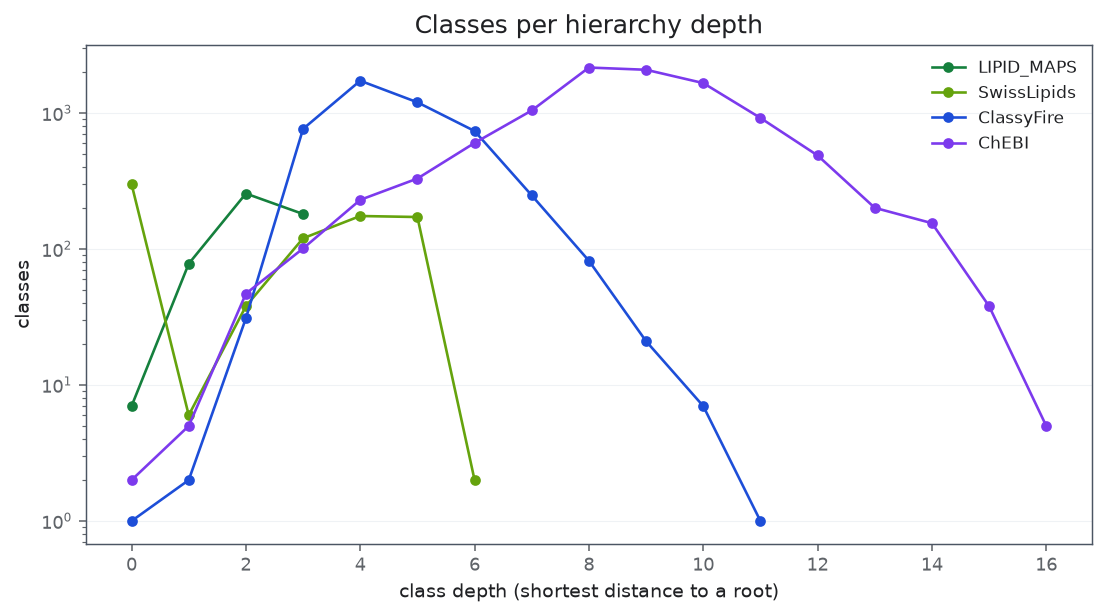

In [2]:
summary_table = table("taxonomy_summary.csv")
display(summary_table.round(3))
depths = table("class_depths.csv")

# --- what this figure shows -------------------------------------------------
MAX_DEPTH = 16
# ---------------------------------------------------------------------------
figure, axis = plt.subplots(figsize=(8, 4.5))
for taxonomy in TAXONOMIES:
    rows = depths[(depths.taxonomy == taxonomy) & (depths.depth <= MAX_DEPTH)]
    axis.plot(rows.depth, rows.classes, marker="o", color=plots.taxonomy_color(taxonomy), label=taxonomy)
axis.set_yscale("log")
axis.set_xlabel("class depth (shortest distance to a root)")
axis.set_ylabel("classes")
axis.legend(frameon=False)
axis.set_title("Classes per hierarchy depth")
plt.tight_layout()

### Remarks

- SwissLipids has 300 roots: ≈ 300 of its 813 classes are not linked to any parent class in the export, so their depth is 0 and they appear next to the single `Lipid` root; SwissLipids depths are therefore only meaningful within its connected hierarchy.
- 33 % of HMDB compounds have no ClassyFire assignment; as unclassified candidates they prevent certainty even at the ClassyFire root (certain fraction 0.89 instead of 1 at depth 0, kidney `formula`).
- ChEBI is a genuine DAG (40 % of classes have several parents, 1.39 direct memberships per compound) with depth up to 16.
- ClassyFire is loaded with the canonical direct-parent lineage; with HMDB alternative parents enabled, only 10 of 511 (kidney) and 14 of 486 (brain) observed ions had a unique certain superclass, because alternative parents add unrelated branches.

### Notes

## Certainty of ion classes as a function of hierarchy depth

### Methodology

#### Theoretical

For depth $d$, taxonomy $T$ and resolution mode, the *certain fraction* is

$$
f_{\mathrm{cert}}(d) = \frac{|\{m : \exists c \in C^{\mathrm{cert}}_T(m),\, d(c) = d\}|}{|\{m : S_T(m) \neq \emptyset\}|},
$$

the share of resolved ions with a certain class at that depth, and the *possible fraction* $f_{\mathrm{poss}}(d)$ is defined analogously with $C^{\mathrm{poss}}_T$. The gap $f_{\mathrm{poss}}(d) - f_{\mathrm{cert}}(d)$ is the fraction of ions whose class at depth $d$ is undetermined because candidate structures disagree. $f_{\mathrm{poss}}$ also decreases with depth when hierarchies stop before reaching depth $d$ for some compounds.

The level that maximizes specificity while keeping $f_{\mathrm{cert}}$ high is the natural supervision level of a chemical-class head.

#### Implementation

Computed from the class evidence of each collection (`level_profile.csv`): for every ion, taxonomy and resolution mode, each class in the candidates' closures is marked certain if all candidates contain it. Counts per depth are divided by the number of resolved ions of that taxonomy and mode.

#### Figure descriptions

*Figure 2.* One panel per collection and resolution mode. $x$: class depth; $y$: fraction of resolved ions. Solid lines with circles: $f_{\mathrm{cert}}(d)$; dashed lines: $f_{\mathrm{poss}}(d)$; colour: taxonomy. The vertical distance between the dashed and the solid line of a taxonomy is the fraction of ions made ambiguous by isomers at that depth.

depth                                    0     1     2     3     4     5     6
collection resolution    taxonomy                                             
brain      formula       ChEBI        1.00  0.98  0.98  0.98  0.97  0.97  0.70
                         ClassyFire   0.85  0.85  0.66  0.62  0.50  0.32  0.15
                         LIPID_MAPS   0.92  0.65  0.48  0.00   NaN   NaN   NaN
                         SwissLipids  0.80  0.80  0.69  0.56  0.01  0.00   NaN
           metaspace_ids ChEBI        1.00  0.99  0.99  0.99  0.99  0.99  0.90
                         ClassyFire   0.99  0.99  0.87  0.83  0.70  0.54  0.19
                         LIPID_MAPS   0.96  0.78  0.62  0.00   NaN   NaN   NaN
                         SwissLipids  0.96  0.96  0.86  0.78  0.02  0.00   NaN
kidney     formula       ChEBI        1.00  0.97  0.96  0.96  0.96  0.96  0.61
                         ClassyFire   0.89  0.89  0.60  0.51  0.42  0.27  0.10
                         LIPID_MAPS   0.86  0.57  0.40  0.01   NaN   NaN   NaN
                         SwissLipids  0.78  0.76  0.70  0.59  0.01  0.00   NaN
           metaspace_ids ChEBI        1.00  1.00  1.00  1.00  0.99  0.99  0.89
                         ClassyFire   0.99  0.99  0.83  0.75  0.64  0.44  0.12
                         LIPID_MAPS   0.93  0.75  0.59  0.01   NaN   NaN   NaN
                         SwissLipids  0.95  0.95  0.87  0.79  0.01  0.00   NaN

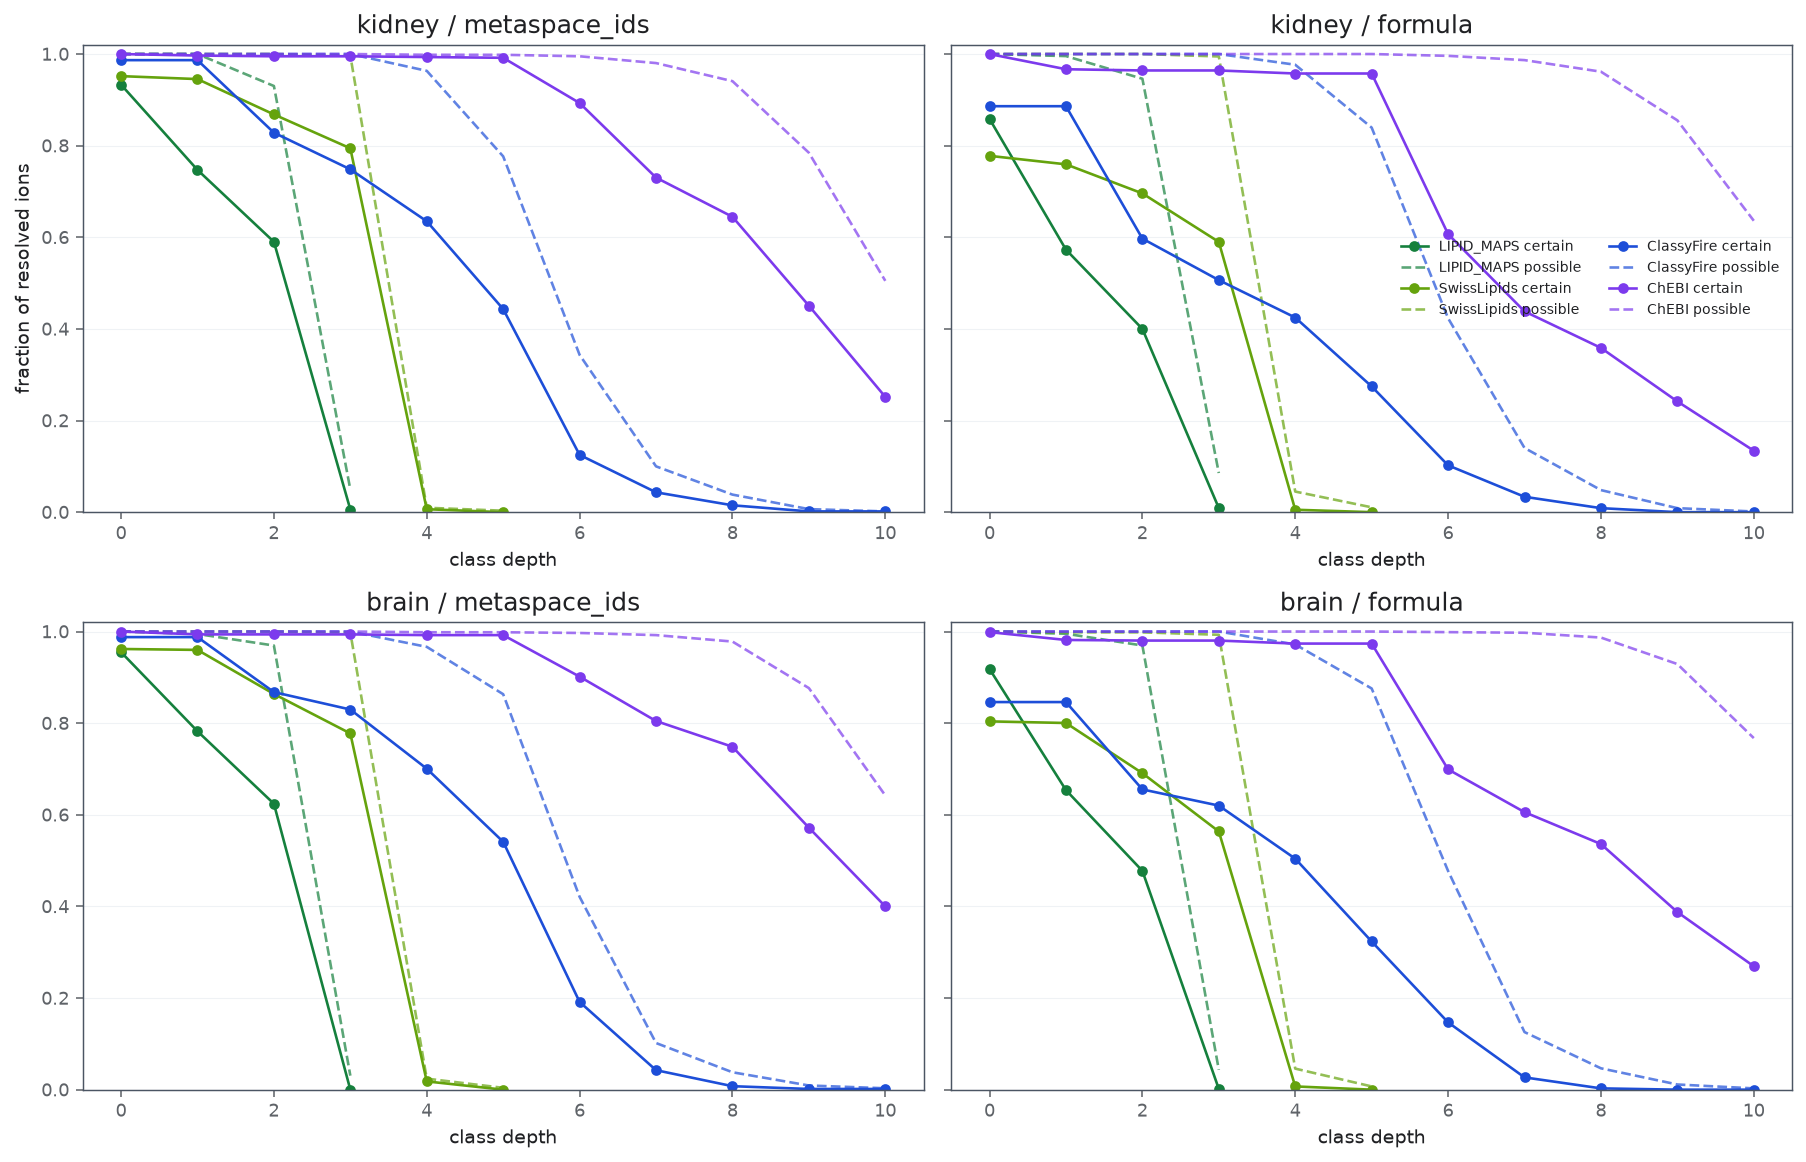

In [3]:
profile = table("level_profile.csv")
profile["certain_fraction"] = profile.ions_certain / profile.resolved_ions
profile["possible_fraction"] = profile.ions_possible / profile.resolved_ions
profile["unambiguous_fraction"] = profile.ions_unambiguous / profile.resolved_ions

# --- what this figure shows -------------------------------------------------
MAX_DEPTH = 10
RESOLUTIONS = ["metaspace_ids", "formula"]
# ---------------------------------------------------------------------------
figure, axes = plt.subplots(len(COLLECTIONS), len(RESOLUTIONS), figsize=(13, 4.2 * len(COLLECTIONS)), sharey=True, squeeze=False)
for row, collection in enumerate(COLLECTIONS):
    for column, resolution in enumerate(RESOLUTIONS):
        axis = axes[row, column]
        for taxonomy in TAXONOMIES:
            rows = profile[(profile.collection == collection) & (profile.resolution == resolution)
                           & (profile.taxonomy == taxonomy) & profile.depth.between(0, MAX_DEPTH)].sort_values("depth")
            color = plots.taxonomy_color(taxonomy)
            axis.plot(rows.depth, rows.certain_fraction, marker="o", color=color, label=f"{taxonomy} certain")
            axis.plot(rows.depth, rows.possible_fraction, linestyle="--", color=color, alpha=0.7, label=f"{taxonomy} possible")
        axis.set_title(f"{collection} / {resolution}")
        axis.set_xlabel("class depth")
        axis.set_ylim(0, 1.02)
axes[0, 0].set_ylabel("fraction of resolved ions")
axes[0, -1].legend(fontsize=7, frameon=False, ncols=2)
plt.tight_layout()
display(profile[profile.depth.between(0, 6)].pivot_table(index=["collection", "resolution", "taxonomy"], columns="depth",
                                                          values="certain_fraction").round(2))

### Remarks

- Kidney, `formula`: LIPID MAPS category 0.86 → main class 0.57 → sub class 0.40 certain; SwissLipids class (depth 2) 0.70 → depth 3 0.59; ClassyFire superclass 0.60 → class 0.51 → subclass 0.42. `metaspace_ids` raises certainty by 0.1–0.2 at each level.
- ChEBI stays ≥ 0.96 certain down to depth 5 only because those levels consist of generic structural classes shared by almost all candidates; certainty drops to 0.61 at depth 6.

### Notes

## Agreement between taxonomies on the same ions

### Methodology

#### Theoretical

For two taxonomies $T_a, T_b$ at depths $d_a, d_b$, every ion with exactly one certain class at $d_a$ in $T_a$ and exactly one at $d_b$ in $T_b$ receives two labels. The adjusted mutual information (AMI) between the two labelings is 1 when the partitions coincide up to renaming and about 0 when they are independent. High AMI at some level pair means that the taxonomies express the same chemical grouping there, so combining them adds redundant rather than complementary relations. The contingency table shows how classes of one taxonomy map onto the other.

#### Implementation

`taxonomy_agreement.csv` holds AMI for all taxonomy pairs and depth pairs up to depth 6 with at least 10 jointly labelled ions and at least two classes on each side (`sklearn.metrics.adjusted_mutual_info_score`; a constant labelling has AMI 1 by convention and is excluded). The contingency table is a cross-tabulation of `ion_unique_classes.csv` (ions with exactly one certain class at the given depth).

#### Figure descriptions

*Figure 3.* Left: AMI (colour) between depth $d_a$ of taxonomy A (rows) and depth $d_b$ of taxonomy B (columns), for the selected pair, collection and resolution; empty cells have fewer than 10 jointly labelled ions or a single class on one side (AMI undefined in substance). Right: contingency table of ion counts between the classes of the two selected levels; each row is a class of taxonomy A, each column a class of taxonomy B. A near-diagonal block structure means consistent partitions.

,taxonomy_a,depth_a,taxonomy_b,depth_b,ions,classes_a,classes_b,ami,collection,resolution
205,ClassyFire,6,LIPID_MAPS,2,50,11,11,1.000,brain,formula
225,LIPID_MAPS,1,SwissLipids,2,241,15,14,0.989,brain,formula
213,ClassyFire,4,SwissLipids,2,130,17,17,0.971,brain,formula
187,ChEBI,6,LIPID_MAPS,0,13,5,4,0.295,brain,formula
185,ChEBI,6,ClassyFire,1,14,5,2,0.220,brain,formula
189,ChEBI,6,SwissLipids,1,11,2,4,-0.052,brain,formula
151,ClassyFire,5,LIPID_MAPS,2,211,31,32,0.994,brain,metaspace_ids
174,LIPID_MAPS,1,SwissLipids,2,277,17,13,0.986,brain,metaspace_ids
169,ClassyFire,6,SwissLipids,3,49,8,9,0.975,brain,metaspace_ids
134,ChEBI,6,ClassyFire,2,16,7,4,0.536,brain,metaspace_ids


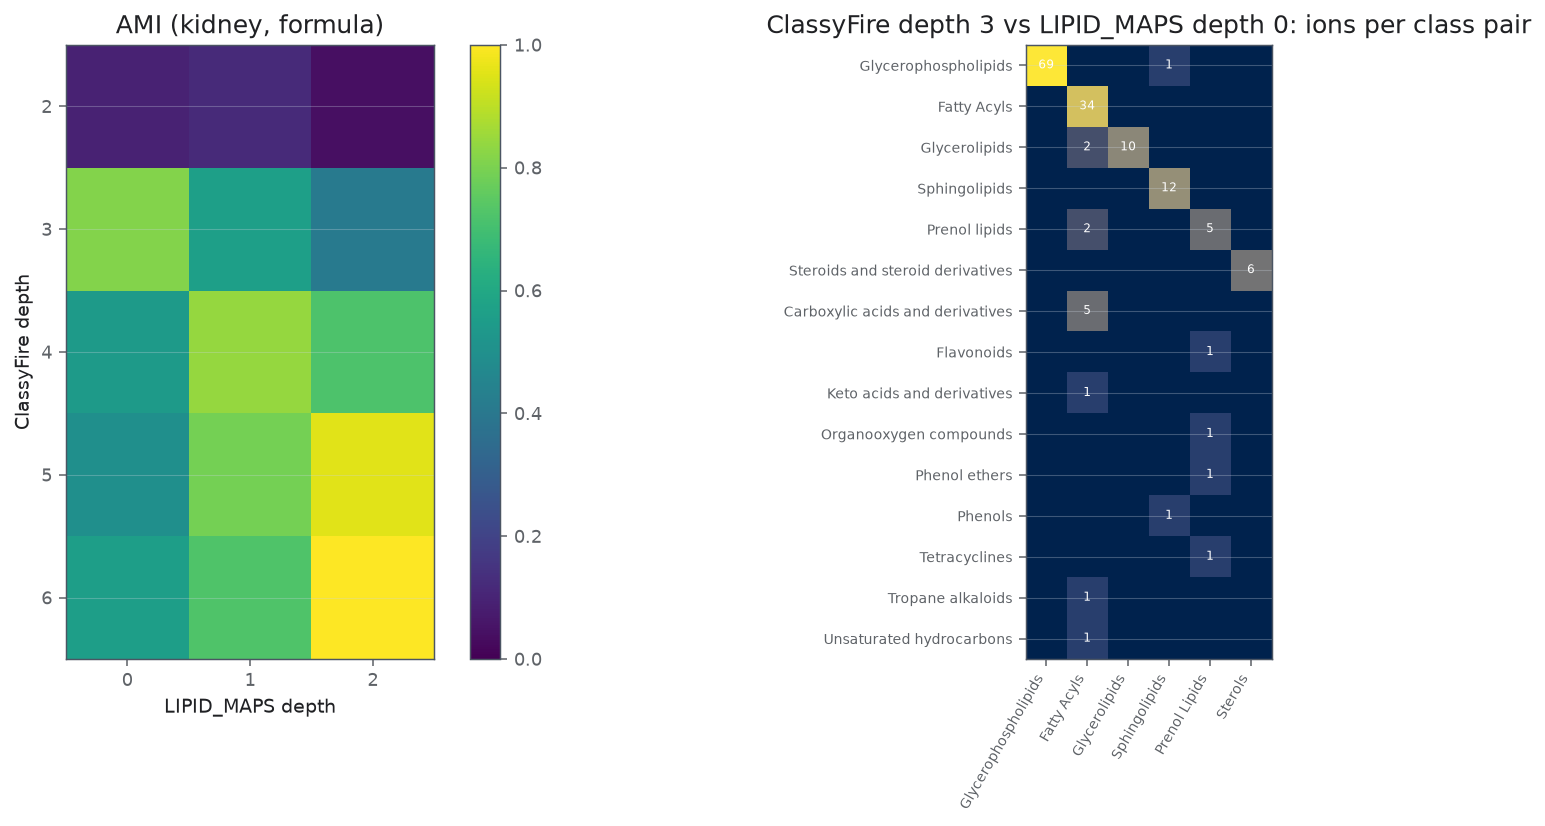

In [4]:
agreement = table("taxonomy_agreement.csv")
unique = table("ion_unique_classes.csv")
display(agreement.sort_values("ami", ascending=False).groupby(["collection", "resolution", "taxonomy_a", "taxonomy_b"]).head(1)
        .sort_values(["collection", "resolution", "ami"], ascending=[True, True, False]).round(3).head(24))

# --- what this figure shows -------------------------------------------------
COLLECTION = "kidney"
RESOLUTION = "formula"
PAIR = ("ClassyFire", "LIPID_MAPS")       # (taxonomy A, taxonomy B), alphabetical as stored
LEVELS = ((3, 0), )                        # (depth A, depth B): ClassyFire class vs LIPID MAPS category
TOP = 15
# ---------------------------------------------------------------------------
rows = agreement[(agreement.collection == COLLECTION) & (agreement.resolution == RESOLUTION)
                 & (agreement.taxonomy_a == PAIR[0]) & (agreement.taxonomy_b == PAIR[1])]
matrix = rows.pivot_table(index="depth_a", columns="depth_b", values="ami")
figure, axes = plt.subplots(1, 2, figsize=(15, 6), gridspec_kw={"width_ratios": [1, 2]})
handle = axes[0].imshow(matrix, cmap=THEME.probability_colormap, vmin=0, vmax=1)
axes[0].set_xticks(range(matrix.shape[1]), matrix.columns)
axes[0].set_yticks(range(matrix.shape[0]), matrix.index)
axes[0].set_xlabel(f"{PAIR[1]} depth")
axes[0].set_ylabel(f"{PAIR[0]} depth")
axes[0].set_title(f"AMI ({COLLECTION}, {RESOLUTION})")
plt.colorbar(handle, ax=axes[0], fraction=0.046)
depth_a, depth_b = LEVELS[0]
subset = unique[(unique.collection == COLLECTION) & (unique.resolution == RESOLUTION)]
left = subset[(subset.taxonomy == PAIR[0]) & (subset.depth == depth_a)].set_index("ion_id").name
right = subset[(subset.taxonomy == PAIR[1]) & (subset.depth == depth_b)].set_index("ion_id").name
joined = pd.concat([left.rename("a"), right.rename("b")], axis=1, join="inner")
crosstab = pd.crosstab(joined.a, joined.b)
crosstab = crosstab.loc[crosstab.sum(axis=1).nlargest(TOP).index, crosstab.sum(axis=0).nlargest(TOP).index]
crosstab = crosstab[sorted(crosstab.columns, key=lambda c: (crosstab[c].to_numpy().argmax(), -crosstab[c].max()))]  # diagonal order
axes[1].imshow(np.log1p(crosstab), cmap=THEME.image_colormap)
axes[1].set_xticks(range(crosstab.shape[1]), [c[:30] for c in crosstab.columns], rotation=60, ha="right", fontsize=7)
axes[1].set_yticks(range(crosstab.shape[0]), [c[:40] for c in crosstab.index], fontsize=7)
for (i, j), value in np.ndenumerate(crosstab.to_numpy()):
    if value:
        axes[1].text(j, i, int(value), ha="center", va="center", fontsize=6, color="white")
axes[1].set_title(f"{PAIR[0]} depth {depth_a} vs {PAIR[1]} depth {depth_b}: ions per class pair")
plt.tight_layout()

### Remarks

- LIPID MAPS and SwissLipids partition lipids almost identically (AMI 0.97–0.99 between LM main/sub class and SL depth 2/3).
- ClassyFire's deep lipid branch (depths 4–6) reproduces LIPID MAPS sub classes (AMI 0.94–1.0), i.e. its lipid part is derived from LIPID MAPS.
- ChEBI agrees weakly with all other taxonomies (AMI ≤ 0.3 in most comparisons; up to 0.77 on ≤ 27 ions).

### Notes

## Results / Summary

### LLM

**Observed.** Certainty of ion classes falls quickly with depth: with `formula` resolution in kidney, 57 % of resolved lipid ions have a certain LIPID MAPS main class (PC, PE, ...) and 40 % a certain sub class; ClassyFire class/subclass are certain for 51 % / 42 %. LIPID MAPS and SwissLipids give nearly identical partitions (AMI ≈ 0.97–0.99), and ClassyFire's lipid branch mirrors LIPID MAPS. ChEBI is near-certain only at generic levels and agrees poorly with the others.

**Interpretation.** The informative supervision level for lipids is the main class (LIPID MAPS depth 1 / SwissLipids depth 2): it is the deepest level certain for a majority of ions. Sub classes are certain for fewer than half of the ions and should enter with soft (`weighted`) labels or masking. Combining LIPID MAPS with SwissLipids is largely redundant; ClassyFire adds coverage for non-lipids. ChEBI adds generic classes rather than discriminative ones.

**Caveats.** Depth is not comparable across taxonomies; SwissLipids contains many unlinked classes; certainty is relative to the structures known to each taxonomy, not experimental identification.

### Person